# 04c · Does the ranking depend on the section geometry?

Same protocol (fixed test set with a boundary band, sizes 20 to 320, seeds 0 to 4, matched tuning) on the 3 ft x 3 ft and
5 ft x 2.5 ft sections generated in `01_data/02_extra_sections_generation.ipynb`. The main section results are read from 02 and 03.

In [1]:
# Make the project helper package (qsvm_rc) importable from any sub-folder
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().resolve()
while not (PROJECT_ROOT / "qsvm_rc").is_dir() and PROJECT_ROOT != PROJECT_ROOT.parent:
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
print("Project root:", PROJECT_ROOT)

Project root: /kaggle/working/Project


In [2]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from qsvm_rc import config, data_utils, metrics, models, plots

EXTRA_SECTIONS = ["3x3", "5x2_5"]
ANGLE_SPEC = {"kind": "angle"}
ZZ_SPEC = {"kind": "zz", "reps": 2, "entanglement": "linear"}

In [3]:
section_frames = []
for section_key in EXTRA_SECTIONS:
    print(f"\nSection {section_key}")
    frame = data_utils.load_section(section_key)
    splits = data_utils.load_splits(section_key)
    scaler = data_utils.domain_scaler(section_key, frame)
    test_rows, band_mask = data_utils.test_indices(splits)
    x_test, _ = data_utils.features_and_labels(frame, test_rows, scaler)
    test_cache = models.ExactStateCache(x_test)
    section_models = {
        "majority": models.classical_fit_predict("majority"),
        "logistic": models.classical_fit_predict("logistic"),
        "rbf_svm": models.classical_fit_predict("rbf_svm"),
        "mlp": models.classical_fit_predict("mlp"),
        "qsvm_angle": models.qsvm_fit_predict(ANGLE_SPEC, test_cache),
        "qsvm_zz": models.qsvm_fit_predict(ZZ_SPEC, test_cache),
    }
    results_dir = config.section_results_dir(section_key, "learning_curves")
    section_frames.append(models.run_learning_curve(section_models, frame, splits, scaler,
                                                    save_path = results_dir / "learning_curves_random.csv", verbose = False))


Section 3x3

Section 5x2_5


In [4]:
# Main section rows from notebooks 02 and 03
main_frames = []
for path in [config.section_results_dir(config.MAIN_SECTION, "classical") / "learning_curves_random.csv",
             config.section_results_dir(config.MAIN_SECTION, "qsvm") / "learning_curves_random.csv"]:
    if path.exists():
        main_frames.append(pd.read_csv(path))
all_sections = pd.concat(section_frames + main_frames, ignore_index = True)
all_sections = all_sections[all_sections["model"].isin(["majority", "logistic", "rbf_svm", "mlp", "qsvm_angle", "qsvm_zz"])]
all_sections = all_sections.drop_duplicates(subset = ["section", "model", "train_size", "train_seed"])
all_sections.to_csv(config.RESULTS_ROOT / "all_sections_learning_curves.csv", index = False)
metrics.mean_ci_table(all_sections, ["band_error", "test_balanced_accuracy", "test_false_safe_rate"],
                      ("section", "model", "train_size"))

band_error test_balanced_accuracy  \
section model    train_size                                           
3x2     logistic 20          0.464 +/- 0.019        0.912 +/- 0.042   
                 40          0.432 +/- 0.042        0.951 +/- 0.023   
                 80          0.404 +/- 0.066        0.958 +/- 0.020   
                 160         0.411 +/- 0.052        0.965 +/- 0.010   
                 320         0.405 +/- 0.075        0.971 +/- 0.005   
...                                      ...                    ...   
5x2_5   rbf_svm  20          0.454 +/- 0.035        0.883 +/- 0.094   
                 40          0.418 +/- 0.079        0.940 +/- 0.061   
                 80          0.414 +/- 0.078        0.966 +/- 0.012   
                 160         0.369 +/- 0.057        0.969 +/- 0.013   
                 320         0.272 +/- 0.078        0.985 +/- 0.005   

                            test_false_safe_rate  
section model    train_size                       
3x2     logistic 20              0.039 +/- 0.052  
                 40              0.022 +/- 0.019  
                 80              0.013 +/- 0.013  
                 160             0.024 +/- 0.012  
                 320             0.021 +/- 0.013  
...                                          ...  
5x2_5   rbf_svm  20              0.043 +/- 0.039  
                 40              0.047 +/- 0.046  
                 80              0.027 +/- 0.020  
                 160             0.011 +/- 0.014  
                 320             0.009 +/- 0.001  

[90 rows x 3 columns]

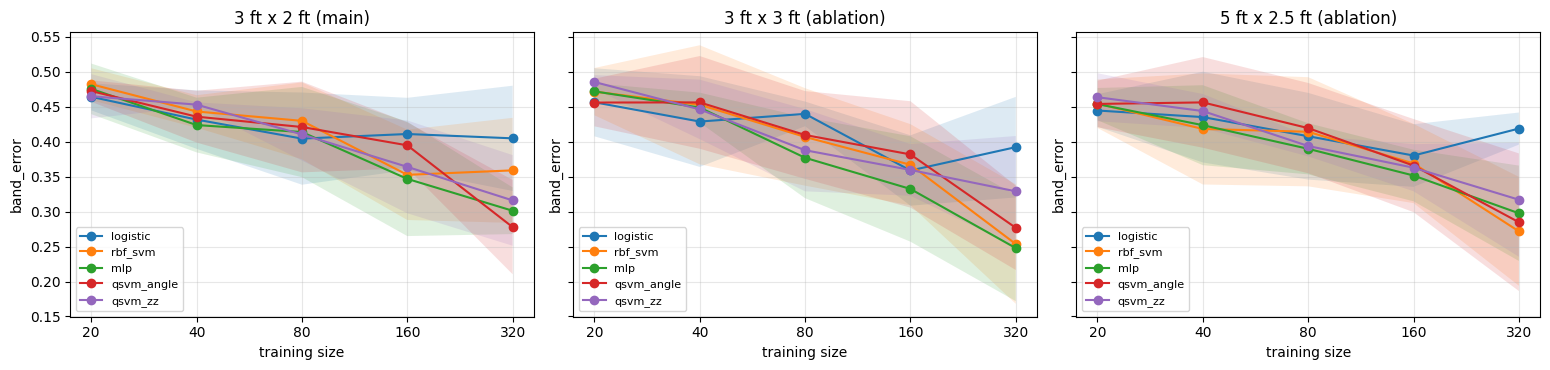

In [5]:
section_keys = [key for key in config.SECTIONS if key in all_sections["section"].unique()]
figure, axes = plt.subplots(1, len(section_keys), figsize = (5.2 * len(section_keys), 3.8), sharey = True)
axes = np.atleast_1d(axes)
for axis, section_key in zip(axes, section_keys):
    part = all_sections[(all_sections["section"] == section_key) & (all_sections["model"] != "majority")]
    plots.learning_curve_plot(part, "band_error", axis = axis, title = config.SECTIONS[section_key]["title"])
figure.tight_layout()
figure.savefig(config.figures_dir() / "sections_band_error.png", dpi = 200)
plt.show()

In [6]:
# Ranking by mean band error at each size, per section (1 = best)
ranking = (all_sections[all_sections["model"] != "majority"]
           .groupby(["section", "train_size", "model"])["band_error"].mean()
           .groupby(level = [0, 1]).rank().unstack("model"))
ranking.to_csv(config.RESULTS_ROOT / "sections_ranking.csv")
ranking

model               logistic  mlp  qsvm_angle  qsvm_zz  rbf_svm
section train_size                                             
3x2     20               1.0  4.0         3.0      2.0      5.0
        40               2.0  1.0         3.0      5.0      4.0
        80               1.0  3.0         4.0      2.0      5.0
        160              5.0  1.0         4.0      3.0      2.0
        320              5.0  2.0         1.0      3.0      4.0
3x3     20               2.0  4.0         1.0      5.0      3.0
        40               1.0  3.0         5.0      2.0      4.0
        80               5.0  1.0         4.0      2.0      3.0
        160              2.0  1.0         5.0      3.0      4.0
        320              5.0  1.0         3.0      4.0      2.0
5x2_5   20               1.0  2.0         3.0      5.0      4.0
        40               3.0  2.0         5.0      4.0      1.0
        80               3.0  1.0         5.0      2.0      4.0
        160              5.0  1.0         3.0      2.0      4.0
        320              5.0  3.0         2.0      4.0      1.0

In [7]:
# Falsifier per section
falsifier_rows = []
for section_key in section_keys:
    part = all_sections[all_sections["section"] == section_key]
    for quantum_model in ["qsvm_angle", "qsvm_zz"]:
        pooled = metrics.paired_comparison(part, quantum_model, "rbf_svm", "band_error").iloc[-1]
        falsifier_rows.append({"section": section_key, "model": quantum_model,
                               "mean_difference_vs_rbf": pooled["mean_difference"],
                               "ci95_low": pooled["ci95_low"], "ci95_high": pooled["ci95_high"],
                               "verdict": "supported" if pooled["ci95_high"] < 0 else "rejected"})
falsifier_sections = pd.DataFrame(falsifier_rows)
falsifier_sections.to_csv(config.RESULTS_ROOT / "sections_falsifier.csv", index = False)
falsifier_sections.round(4)

,section,model,mean_difference_vs_rbf,ci95_low,ci95_high,verdict
0,3x2,qsvm_angle,-0.0130,-0.0421,0.0161,rejected
1,3x2,qsvm_zz,-0.0117,-0.0381,0.0147,rejected
2,3x3,qsvm_angle,0.0057,-0.0118,0.0233,rejected
3,3x3,qsvm_zz,0.0112,-0.0109,0.0334,rejected
4,5x2_5,qsvm_angle,0.0106,-0.0044,0.0255,rejected
5,5x2_5,qsvm_zz,0.0107,-0.0081,0.0296,rejected


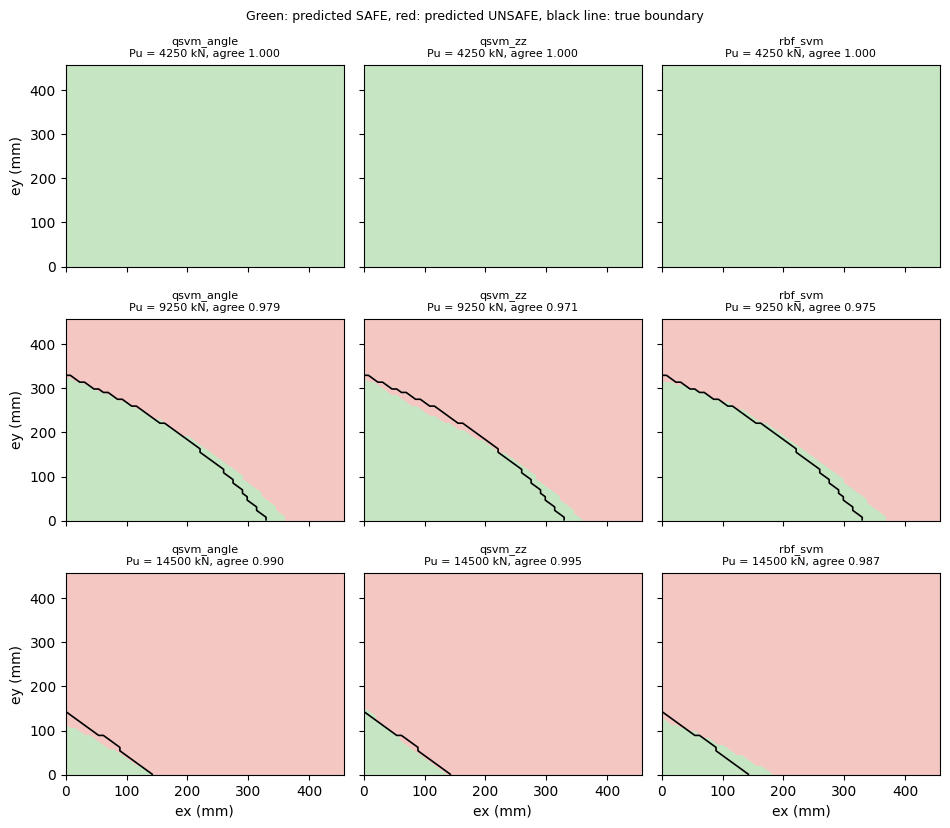

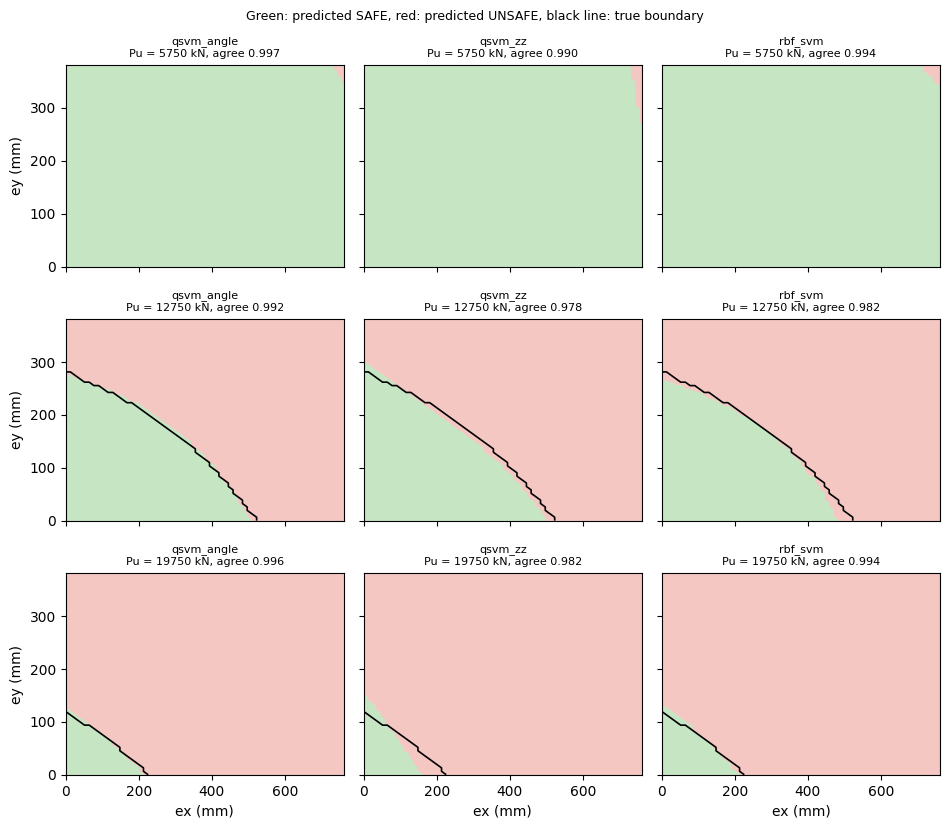

In [8]:
# Predicted SAFE regions for each extra section (n = 320, seed 0)
for section_key in EXTRA_SECTIONS:
    frame = data_utils.load_section(section_key)
    splits = data_utils.load_splits(section_key)
    scaler = data_utils.domain_scaler(section_key, frame)
    x_train, y_train = data_utils.features_and_labels(frame, data_utils.training_indices(splits, 320, 0), scaler)
    seed_zero = config.run_seed(config.SEED, 0)
    predictors = {}
    for name, spec in [("qsvm_angle", ANGLE_SPEC), ("qsvm_zz", ZZ_SPEC)]:
        bandwidth, c_value, _, _ = models.tune_qsvm(spec, x_train, y_train, seed_zero)
        predictors[name] = models.exact_qsvm_predictor(spec, x_train, y_train, bandwidth, c_value)
    predictors["rbf_svm"] = models.fit_classical("rbf_svm", x_train, y_train, seed_zero)[0].predict
    top_load = float(frame["pu_kN"].max())
    levels = [round(fraction * top_load / 250) * 250 for fraction in [0.2, 0.45, 0.7]]
    figure = plots.safe_region_figure(section_key, scaler, predictors, pu_levels = levels)
    figure.savefig(config.figures_dir() / f"safe_regions_{section_key}_n320.png", dpi = 200)
    plt.show()

Next: `05_noise_hardware/01_noise_study_aer.ipynb`.